# 3. Tutorial 3

**Course:** High Switching Frequency Power Converters

## 3.1 Loop inductance estimates

The power loop of a GaN half-bridge runs on layer L1: the copper is $w = 4~\mathrm{mm}$ wide and $l = 10~\mathrm{mm}$ long. The return current flows in a solid plane at the distance $h$ (L2: $0.1~\mathrm{mm}$, L4: $1.5~\mathrm{mm}$).

3.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.integrate.solve_ivp and scipy.signal) and add constant variables for $\mu_0$ and $c_0$.

3.1.2 Create the functions
- `get_L_planes(h, l, w)`: parallel-plane estimate $L = \mu_0 h l / w$,
- `get_Z0_strip(w, h)`: characteristic impedance of a strip over a plane in air (Hammerstad; $Z_0 = 60~\Omega\cdot\ln(8h/w + w/(4h))$ for $w/h \leq 1$ and $Z_0 = 376.7~\Omega/(w/h + 1.393 + 0.667\ln(w/h + 1.444))$ for $w/h \geq 1$),
- `get_L_strip(h, l, w)`: $L = Z_0 l / c_0$,
- `get_L_wire(l, d)`: partial inductance of a round conductor $L_\mathrm{p} = \frac{\mu_0 l}{2\pi}\left[\ln(4l/d) - 1\right]$.

3.1.3 Plot the loop inductance of both estimates versus $h$ in the range [$0.05 \ldots 2~\mathrm{mm}$]. Mark the FastHenry results of the example file `loop_L2_return.inp` ($0.48~\mathrm{nH}$ at $0.1~\mathrm{mm}$, $3.1~\mathrm{nH}$ at $1.5~\mathrm{mm}$; both include vias and the capacitor pad).

3.1.4 For the return on L4, compute the effect of doubling $w$, of halving $l$ and of moving the return to L2. Compute the partial inductance of one via ($d = 0.3~\mathrm{mm}$, $l = 1.5~\mathrm{mm}$).


In [1]:
# Subtask 3.1.1 Import necessary modules and add constant variables for the constant values.
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy import signal

mu_0 = 4e-7 * np.pi   # Unit H/m
c_0 = 2.998e8         # Unit m/s
w, l = 4e-3, 10e-3    # Unit m


# Subtask 3.1.2 Inductance estimates
def get_L_planes(h, l, w):
    """Parallel-plane estimate in H (valid for w >> h)."""
    return mu_0 * h * l / w


def get_Z0_strip(w, h):
    """Characteristic impedance in Ohm of a thin strip over a plane in air (Hammerstad)."""
    u = np.asarray(w / h, dtype=float)
    narrow = 376.7 / (2 * np.pi) * np.log(8 / u + u / 4)
    wide = 376.7 / (u + 1.393 + 0.667 * np.log(u + 1.444))
    return np.where(u <= 1, narrow, wide)


def get_L_strip(h, l, w):
    """Inductance in H of a strip of length l over a plane: L = Z0 l / c0."""
    return get_Z0_strip(w, h) * l / c_0


def get_L_wire(l, d):
    """Partial self-inductance in H of a round conductor (l >> d, current at the surface)."""
    return mu_0 * l / (2 * np.pi) * (np.log(4 * l / d) - 1)


for h in [0.1e-3, 1.5e-3]:
    print(f"h = {h*1e3:.1f} mm: planes {get_L_planes(h, l, w)*1e9:.2f} nH, strip {get_L_strip(h, l, w)*1e9:.2f} nH "
          f"(Z0 = {get_Z0_strip(w, h):.2f} Ohm)")


h = 0.1 mm: planes 0.31 nH, strip 0.29 nH (Z0 = 8.59 Ohm)
h = 1.5 mm: planes 4.71 nH, strip 2.51 nH (Z0 = 75.30 Ohm)


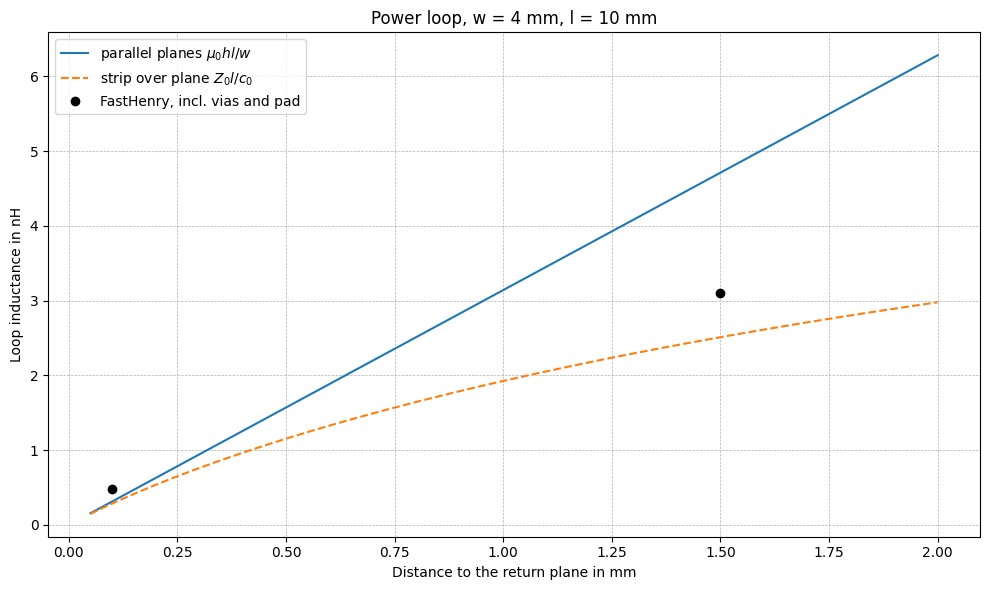

return on L4: 2.51 nH
  w doubled:  1.57 nH
  l halved:   1.26 nH
  return L2:  0.29 nH
one via, 1.5 mm, d = 0.3 mm: 0.60 nH


In [2]:
if __name__ == "__main__":
    # Subtask 3.1.3 Loop inductance versus distance to the return plane
    h = np.linspace(0.05e-3, 2e-3, 400)
    plt.figure(figsize=(10, 6))
    plt.plot(h * 1e3, get_L_planes(h, l, w) * 1e9, label=r'parallel planes $\mu_0 h l/w$')
    plt.plot(h * 1e3, get_L_strip(h, l, w) * 1e9, '--', label=r'strip over plane $Z_0 l/c_0$')
    plt.plot([0.1, 1.5], [0.48, 3.1], 'ko', label='FastHenry, incl. vias and pad')
    plt.xlabel('Distance to the return plane in mm')
    plt.ylabel('Loop inductance in nH')
    plt.title('Power loop, w = 4 mm, l = 10 mm')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 3.1.4 Which change helps most (return on L4)?
    L4 = get_L_strip(1.5e-3, l, w)
    print(f"return on L4: {L4*1e9:.2f} nH")
    print(f"  w doubled:  {get_L_strip(1.5e-3, l, 2*w)*1e9:.2f} nH")
    print(f"  l halved:   {get_L_strip(1.5e-3, l/2, w)*1e9:.2f} nH")
    print(f"  return L2:  {get_L_strip(0.1e-3, l, w)*1e9:.2f} nH")
    print(f"one via, 1.5 mm, d = 0.3 mm: {get_L_wire(1.5e-3, 0.3e-3)*1e9:.2f} nH")


### 3.1.4 Solution

For $w \gg h$ both estimates agree; for $w/h \approx 3$ the parallel-plane formula is about twice too high because the field spreads beside the strip. With the return on L4 the strip formula gives $2.5~\mathrm{nH}$; doubling $w$ gives $1.57~\mathrm{nH}$, halving $l$ gives $1.26~\mathrm{nH}$ and moving the return to L2 gives $0.29~\mathrm{nH}$. The distance between forward and return current dominates. One via has a partial inductance of $0.60~\mathrm{nH}$.


## 3.2 Loop inductance from a measured ring

The switch-node ring of a $48~\mathrm{V}$ GaN half-bridge has $f_\mathrm{r0} = 200~\mathrm{MHz}$. With $C_\mathrm{add} = 330~\mathrm{pF}$ across the low-side switch it drops to $f_\mathrm{r1} = 141~\mathrm{MHz}$.

3.2.1 Create the function `get_Cpar_L(f0, f1, C_add)` which returns $C_\mathrm{par}$ and $L_\mathrm{loop}$. Print both and $Z_0$.

3.2.2 The added capacitor has an ESL. Plot the value of $C_\mathrm{par}$ that the method returns versus the ESL in the range [$0 \ldots 1~\mathrm{nH}$], if the true values are those of 3.2.1. (Hint: at $f_\mathrm{r1}$ the capacitor appears as $C_\mathrm{add}/(1 - \omega^2 L_\mathrm{ESL} C_\mathrm{add})$.)

3.2.3 Simulate the switch-node voltage at the turn-on of the high-side switch as a series $R$-$L$-$C$ circuit driven by a $48~\mathrm{V}$ ramp of duration $t_\mathrm{r}$ ($R = 0.05~\Omega$). Plot $v(t)$ for $t_\mathrm{r} = 1$, $2.5$ and $5~\mathrm{ns}$ and compare the peaks with $V_\mathrm{DC}(1 + |\sin x|/x)$, $x = \pi f_\mathrm{r0} t_\mathrm{r}$.


In [3]:
# Subtask 3.2.1 C_par and L_loop from two ringing frequencies
f_r0, f_r1, C_add = 200e6, 141e6, 330e-12   # Unit Hz, Hz, F
V_DC, I = 48, 10                            # Unit V, A


def get_Cpar_L(f0, f1, C_add):
    """Capacitance across the switch and loop inductance from the ring with and without C_add."""
    C_par = C_add / ((f0 / f1)**2 - 1)
    L = 1 / ((2 * np.pi * f0)**2 * C_par)
    return C_par, L


C_par, L_loop = get_Cpar_L(f_r0, f_r1, C_add)
Z_0 = np.sqrt(L_loop / C_par)
omega_0 = 1 / np.sqrt(L_loop * C_par)
print(f"C_par = {C_par*1e12:.0f} pF, L_loop = {L_loop*1e9:.2f} nH, Z0 = {Z_0:.2f} Ohm")


C_par = 326 pF, L_loop = 1.94 nH, Z0 = 2.44 Ohm


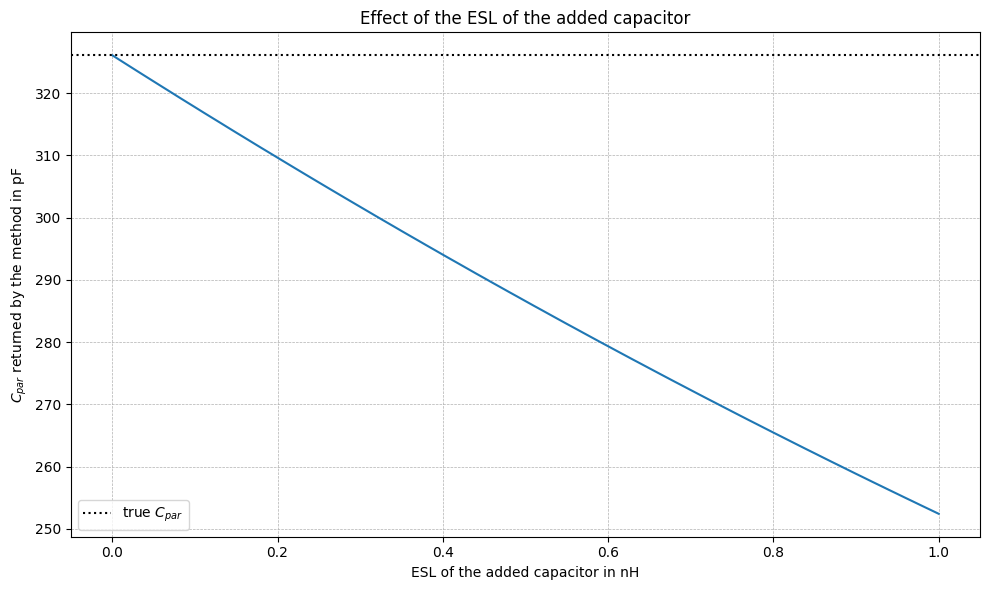

In [4]:
if __name__ == "__main__":
    # Subtask 3.2.2 Error caused by the ESL of the added capacitor
    L_esl = np.linspace(0, 1e-9, 101)
    C_add_app = []
    for Le in L_esl:
        # true circuit: C_par in parallel with (L_esl + C_add); find the new ring frequency numerically
        f = np.linspace(80e6, 200e6, 120001)
        wv = 2 * np.pi * f
        Y = 1j * wv * C_par + 1 / (1j * wv * Le + 1 / (1j * wv * C_add))
        res = 1 + 1j * wv * L_loop * Y            # zero at the series resonance of L_loop with the node
        f1_true = f[np.argmin(np.abs(res.imag) + np.abs(res.real))]
        C_add_app.append(get_Cpar_L(f_r0, f1_true, C_add)[0])
    plt.figure(figsize=(10, 6))
    plt.plot(L_esl * 1e9, np.array(C_add_app) * 1e12)
    plt.axhline(C_par * 1e12, color='black', linestyle=':', label='true $C_{par}$')
    plt.xlabel('ESL of the added capacitor in nH')
    plt.ylabel(r'$C_{par}$ returned by the method in pF')
    plt.title('Effect of the ESL of the added capacitor')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


t_r = 1.0 ns: simulated peak 91.5 V, undamped formula 92.9 V


t_r = 2.5 ns: simulated peak 77.6 V, undamped formula 78.6 V


t_r = 5.0 ns: simulated peak 48.5 V, undamped formula 48.0 V


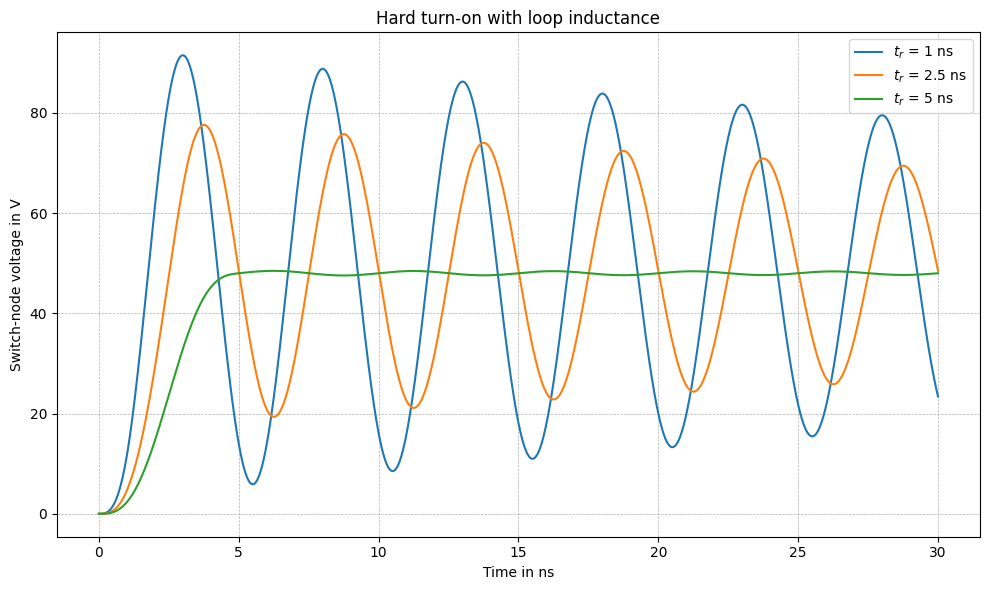

In [5]:
# Subtask 3.2.3 Turn-on of the high-side switch: series R-L-C driven by a voltage ramp
R_loop = 0.05   # Unit Ohm, small damping


def get_turn_on(t_r, C_s=None, R_s=None, t_end=30e-9, n=6001):
    """Switch-node voltage (and snubber current) for a ramp of duration t_r; optional RC snubber."""
    t = np.linspace(0, t_end, n)

    def v_in(tt):
        return V_DC * min(tt / t_r, 1.0)

    def rhs(tt, y):
        i_L, v_p, v_s = y
        i_s = 0.0 if C_s is None else (v_p - v_s) / R_s
        di = (v_in(tt) - v_p - R_loop * i_L) / L_loop
        dvp = (i_L - i_s) / C_par
        dvs = 0.0 if C_s is None else i_s / C_s
        return [di, dvp, dvs]

    sol = solve_ivp(rhs, [0, t_end], [0, 0, 0], t_eval=t, max_step=5e-12, rtol=1e-8, atol=1e-10)
    i_s = np.zeros_like(t) if C_s is None else (sol.y[1] - sol.y[2]) / R_s
    return t, sol.y[1], i_s


if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    for t_r in [1e-9, 2.5e-9, 5e-9]:
        t, v, _ = get_turn_on(t_r)
        x = np.pi * f_r0 * t_r
        print(f"t_r = {t_r*1e9:.1f} ns: simulated peak {v.max():.1f} V, "
              f"undamped formula {V_DC * (1 + abs(np.sin(x)) / x):.1f} V")
        plt.plot(t * 1e9, v, label=f'$t_r$ = {t_r*1e9:g} ns')
    plt.xlabel('Time in ns')
    plt.ylabel('Switch-node voltage in V')
    plt.title('Hard turn-on with loop inductance')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 3.2.3 Solution

$C_\mathrm{par} = 326~\mathrm{pF}$, $L_\mathrm{loop} = 1.94~\mathrm{nH}$, $Z_0 = 2.44~\Omega$. An ESL of $0.4~\mathrm{nH}$ in the added capacitor makes the method underestimate $C_\mathrm{par}$ by about 10 %, so it must be a small part soldered directly across the switch. The peaks follow $V_\mathrm{DC}(1 + |\sin x|/x)$: about $93$, $79$ and $48~\mathrm{V}$ (slightly less with the small damping). An edge as long as one ringing period excites almost no ringing.


## 3.3 Overshoot at turn-off

Use $L_\mathrm{loop}$ and $C = C_\mathrm{par}$ from 3.2.1 and $I = 10~\mathrm{A}$. The channel current falls linearly within $t_\mathrm{f}$; the circuit is lossless (see Task 3.3 of the exercise sheet).

3.3.1 Solve $\ddot{u} + \omega_0^2 u = -\frac{1}{C}\frac{\mathrm{d}i_\mathrm{ch}}{\mathrm{d}t}$ numerically with `solve_ivp` for $t_\mathrm{f} = 0.5$, $1$, $2$ and $4~\mathrm{ns}$ and plot $u(t)$ for $0 \ldots 20~\mathrm{ns}$.

3.3.2 Compare the numerical maxima with the analytical result (maximum of $\frac{L I}{t_\mathrm{f}}(1-\cos\omega_0 t)$ during the fall and $\frac{2LI}{t_\mathrm{f}}|\sin\frac{\omega_0 t_\mathrm{f}}{2}|$ after it).

3.3.3 Plot the maximum overshoot versus $t_\mathrm{f}$ in the range [$0.1 \ldots 20~\mathrm{ns}$] (log axes) together with $L I / t_\mathrm{f}$ and $I Z_0$.


t_f = 0.5 ns: numerical max 24.00 V, analytical 24.00 V, L*I/t_f = 38.8 V, I*Z0 = 24.4 V


t_f = 1.0 ns: numerical max 22.83 V, analytical 22.83 V, L*I/t_f = 19.4 V, I*Z0 = 24.4 V


t_f = 2.0 ns: numerical max 18.47 V, analytical 18.47 V, L*I/t_f = 9.7 V, I*Z0 = 24.4 V


t_f = 4.0 ns: numerical max 9.71 V, analytical 9.71 V, L*I/t_f = 4.9 V, I*Z0 = 24.4 V


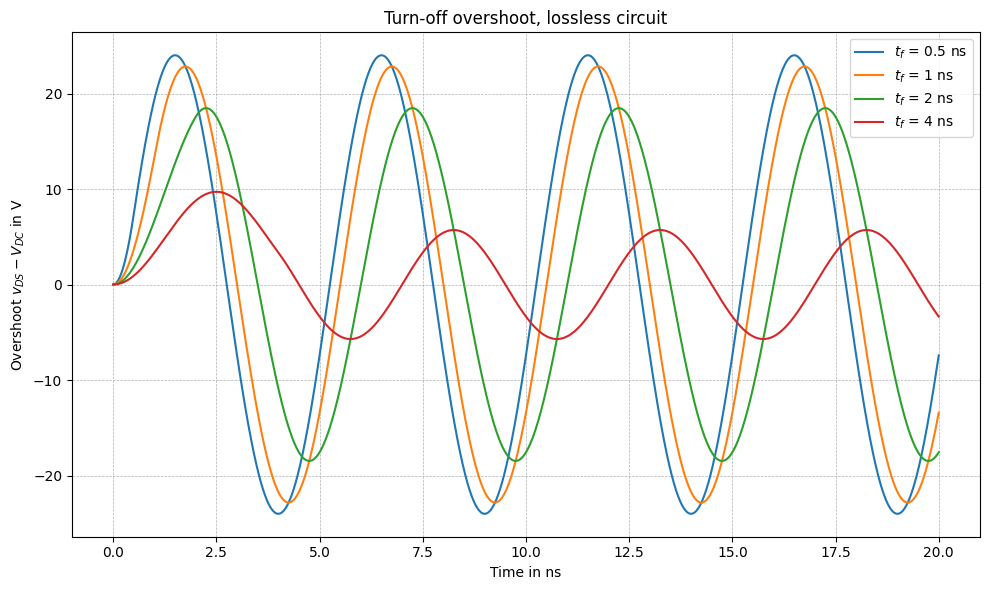

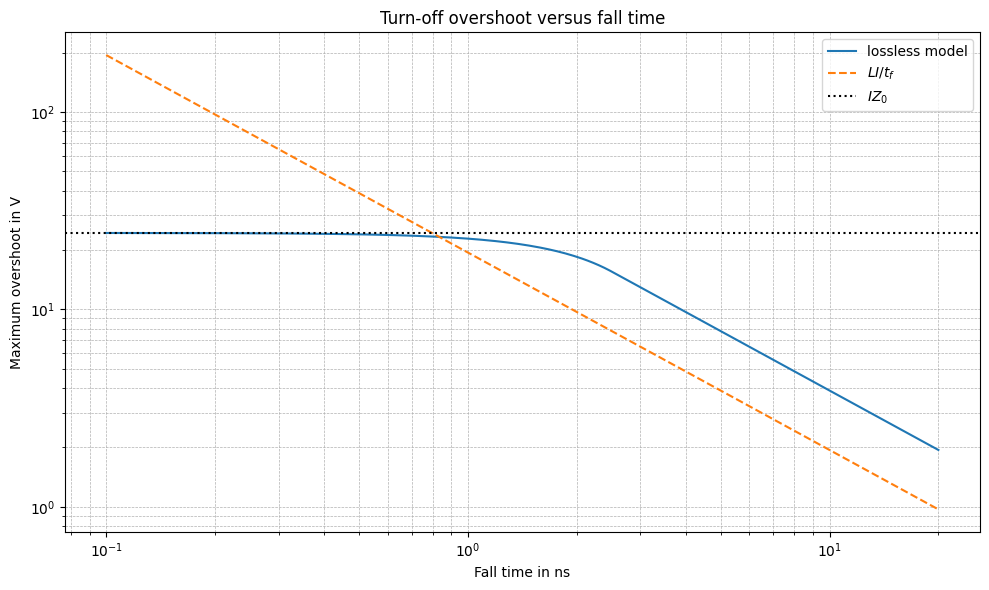

In [6]:
# Subtask 3.3.1 Overshoot at turn-off for a linear current fall


def get_turn_off(t_f, t_end=20e-9, n=4001):
    """Overshoot u = v_DS - V_DC of the lossless circuit for a linear fall of the channel current."""
    t = np.linspace(0, t_end, n)

    def rhs(tt, y):
        u, du = y
        di_ch = -I / t_f if tt < t_f else 0.0
        return [du, -omega_0**2 * u - di_ch / C_par]

    sol = solve_ivp(rhs, [0, t_end], [0, 0], t_eval=t, max_step=2e-12, rtol=1e-9, atol=1e-12)
    return t, sol.y[0]


def get_u_max_analytical(t_f):
    """Maximum overshoot: during the fall and amplitude after it."""
    t = np.linspace(0, t_f, 2001)
    during = np.max(L_loop * I / t_f * (1 - np.cos(omega_0 * t)))
    after = 2 * L_loop * I / t_f * np.abs(np.sin(omega_0 * t_f / 2))
    return max(during, after)


if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    for t_f in [0.5e-9, 1e-9, 2e-9, 4e-9]:
        t, u = get_turn_off(t_f)
        plt.plot(t * 1e9, u, label=f'$t_f$ = {t_f*1e9:g} ns')
        # Subtask 3.3.2 Comparison with the analytical result
        print(f"t_f = {t_f*1e9:.1f} ns: numerical max {u.max():.2f} V, analytical {get_u_max_analytical(t_f):.2f} V, "
              f"L*I/t_f = {L_loop*I/t_f:.1f} V, I*Z0 = {I*Z_0:.1f} V")
    plt.xlabel('Time in ns')
    plt.ylabel(r'Overshoot $v_{DS} - V_{DC}$ in V')
    plt.title('Turn-off overshoot, lossless circuit')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 3.3.3 Maximum overshoot versus fall time
    t_f_range = np.logspace(-10, np.log10(20e-9), 300)
    u_max = np.array([get_u_max_analytical(tf) for tf in t_f_range])
    plt.figure(figsize=(10, 6))
    plt.loglog(t_f_range * 1e9, u_max, label='lossless model')
    plt.loglog(t_f_range * 1e9, L_loop * I / t_f_range, '--', label=r'$L I/t_f$')
    plt.axhline(I * Z_0, color='black', linestyle=':', label=r'$I Z_0$')
    plt.xlabel('Fall time in ns')
    plt.ylabel('Maximum overshoot in V')
    plt.title('Turn-off overshoot versus fall time')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 3.3.3 Solution

The numerical and analytical maxima agree. For $t_\mathrm{f} \ll T_\mathrm{r}$ the overshoot approaches $I Z_0 = 24.4~\mathrm{V}$, while $L I/t_\mathrm{f}$ grows without limit and overestimates it. For $t_\mathrm{f} \gg T_\mathrm{r}$ the lossless model oscillates between $L I/t_\mathrm{f}$ and $2 L I/t_\mathrm{f}$; with damping the voltage settles at $L I/t_\mathrm{f}$. $I Z_0$ is an upper bound for any fall time.


## 3.4 RC snubber

3.4.1 Create the function `get_zeta(r, n)` which returns the damping ratio of the dominant complex pair of roots of $r n p^3 + (1+n) p^2 + r n p + 1 = 0$ ($r = R_\mathrm{s}/Z_0$, $n = C_\mathrm{s}/C_\mathrm{par}$). Plot $\zeta$ versus $r$ in the range [$0.1 \ldots 10$] for $n = 1$, $3.07$ and $10$ and mark the design $R_\mathrm{s} = 2.2~\Omega$, $C_\mathrm{s} = 1~\mathrm{nF}$.

3.4.2 Extend the model of 3.2.3 by the snubber branch and simulate the turn-on ($t_\mathrm{r} = 1~\mathrm{ns}$) with and without snubber. Compute the energy dissipated in $R_\mathrm{s}$ during one edge and compare it with $\frac{1}{2} C_\mathrm{s} V_\mathrm{DC}^2$.

3.4.3 Plot the snubber loss range $\frac{1}{2}C_\mathrm{s}V^2 f_\mathrm{sw} \ldots C_\mathrm{s}V^2 f_\mathrm{sw}$ versus $f_\mathrm{sw}$ in the range [$0.1 \ldots 5~\mathrm{MHz}$] for $48~\mathrm{V}$.


n = 3.07, r = 0.90, zeta = 0.51


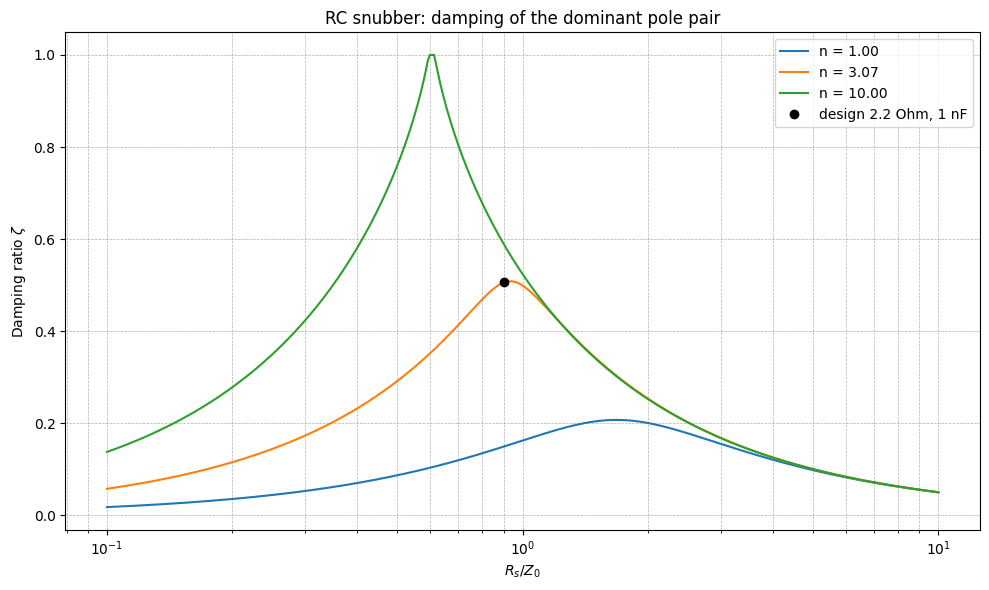

In [7]:
# Subtask 3.4.1 Damping ratio of the ring with an RC snubber


def get_zeta(r, n):
    """Damping ratio of the dominant complex pair of r n p^3 + (1+n) p^2 + r n p + 1 = 0."""
    roots = np.roots([r * n, 1 + n, r * n, 1])
    pairs = [p for p in roots if abs(p.imag) > 1e-9]
    if not pairs:
        return 1.0
    p = max(pairs, key=lambda q: q.imag)
    return -p.real / abs(p)


C_s, R_s = 1e-9, 2.2   # Unit F, Ohm
n_design, r_design = C_s / C_par, R_s / Z_0
print(f"n = {n_design:.2f}, r = {r_design:.2f}, zeta = {get_zeta(r_design, n_design):.2f}")

if __name__ == "__main__":
    r = np.logspace(-1, 1, 400)
    plt.figure(figsize=(10, 6))
    for n in [1, n_design, 10]:
        plt.semilogx(r, [get_zeta(ri, n) for ri in r], label=f'n = {n:.2f}')
    plt.plot(r_design, get_zeta(r_design, n_design), 'ko', label='design 2.2 Ohm, 1 nF')
    plt.xlabel(r'$R_s/Z_0$')
    plt.ylabel(r'Damping ratio $\zeta$')
    plt.title('RC snubber: damping of the dominant pole pair')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


peak without snubber 91.5 V, with snubber 66.6 V
energy in R_s per edge 1418 nJ, 0.5*C_s*V^2 = 1152 nJ


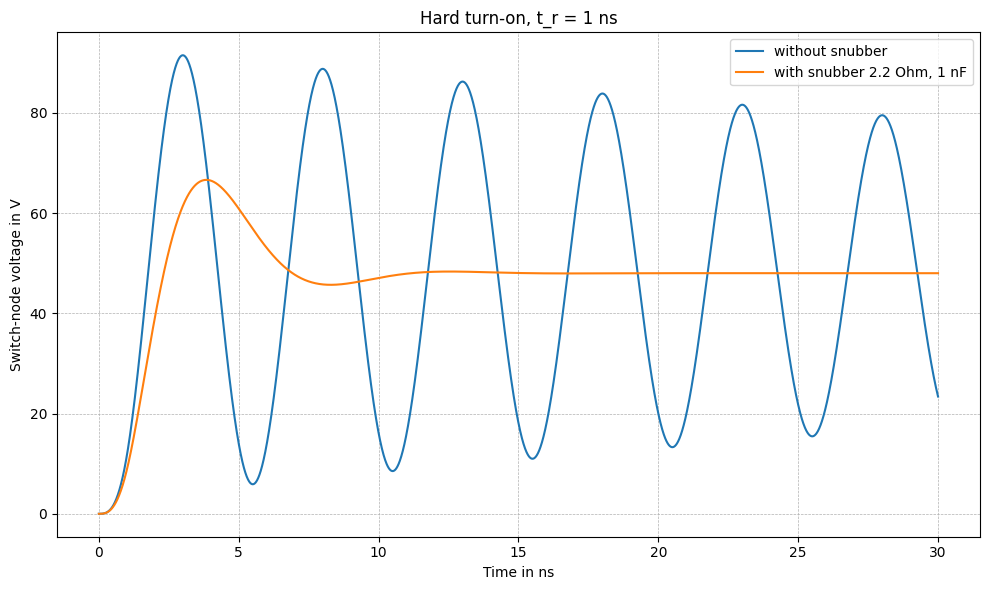

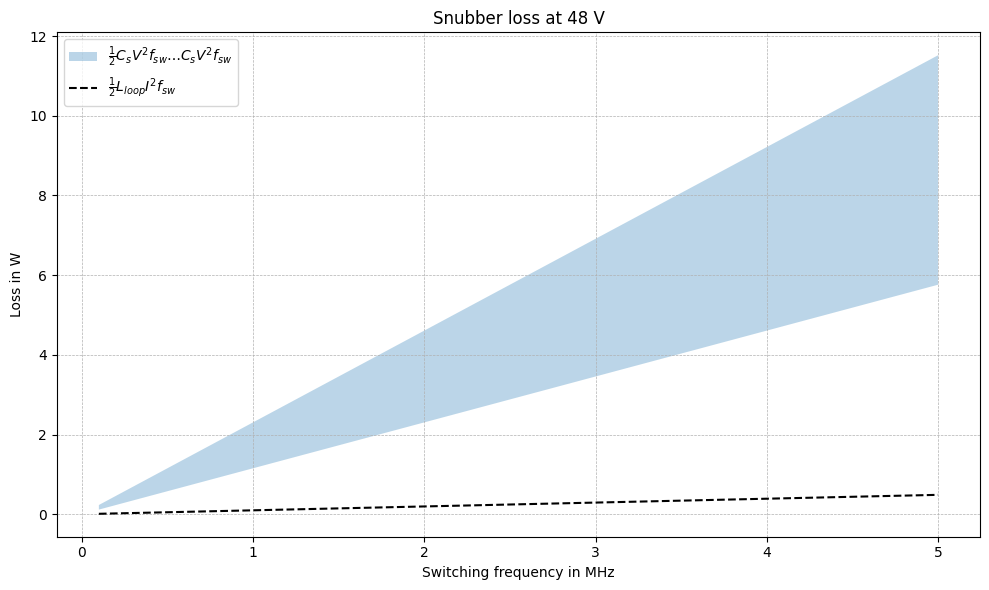

In [8]:
if __name__ == "__main__":
    # Subtask 3.4.2 Turn-on with and without snubber
    t, v0, _ = get_turn_on(1e-9)
    t, v1, i_s = get_turn_on(1e-9, C_s=C_s, R_s=R_s)
    E_R = np.trapezoid(i_s**2 * R_s, t)
    print(f"peak without snubber {v0.max():.1f} V, with snubber {v1.max():.1f} V")
    print(f"energy in R_s per edge {E_R*1e9:.0f} nJ, 0.5*C_s*V^2 = {0.5*C_s*V_DC**2*1e9:.0f} nJ")
    plt.figure(figsize=(10, 6))
    plt.plot(t * 1e9, v0, label='without snubber')
    plt.plot(t * 1e9, v1, label='with snubber 2.2 Ohm, 1 nF')
    plt.xlabel('Time in ns')
    plt.ylabel('Switch-node voltage in V')
    plt.title('Hard turn-on, t_r = 1 ns')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 3.4.3 Snubber loss versus switching frequency
    f_sw = np.linspace(0.1e6, 5e6, 100)
    plt.figure(figsize=(10, 6))
    plt.fill_between(f_sw / 1e6, 0.5 * C_s * V_DC**2 * f_sw, C_s * V_DC**2 * f_sw, alpha=0.3,
                     label=r'$\frac{1}{2}C_sV^2f_{sw} \ldots C_sV^2f_{sw}$')
    plt.plot(f_sw / 1e6, 0.5 * L_loop * I**2 * f_sw, 'k--', label=r'$\frac{1}{2}L_{loop}I^2 f_{sw}$')
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel('Loss in W')
    plt.title('Snubber loss at 48 V')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 3.4.3 Solution

The design $R_\mathrm{s} = 2.2~\Omega$, $C_\mathrm{s} = 1~\mathrm{nF}$ is close to the maximum damping ($\zeta \approx 0.51$) for $n = 3.07$; the peak drops from about $92~\mathrm{V}$ to $67~\mathrm{V}$. In the simulation $R_\mathrm{s}$ dissipates $1.42~\mu\mathrm{J}$ during the fast edge: the charging energy $\frac{1}{2}C_\mathrm{s}V^2 = 1.15~\mu\mathrm{J}$ plus most of the ring energy $\frac{1}{2}C_\mathrm{par}V^2$, which without snubber is dissipated elsewhere in the loop. The snubber therefore adds about $\frac{1}{2}C_\mathrm{s}V^2$ per fast edge, i.e. more than $1~\mathrm{W}$ at $1~\mathrm{MHz}$ and $48~\mathrm{V}$, about ten times $\frac{1}{2}L_\mathrm{loop}I^2 f_\mathrm{sw}$. At MHz frequencies the loop inductance should be reduced first.


## 3.5 Capacitive coupling of the switch node

3.5.1 Compute the capacitance between a switch-node pad of $48~\mathrm{mm^2}$ and an earthed heat sink through a $0.25~\mathrm{mm}$ thermal interface ($\varepsilon_\mathrm{r} = 6$), the common-mode current at $100~\mathrm{V/ns}$ and the charge per edge at $400~\mathrm{V}$.

3.5.2 Create the function `get_vGS(t, R)` for the gate voltage of the low-side switch during the switch-node edge ($C_\mathrm{GD} = 2~\mathrm{pF}$, $C_\mathrm{GS} = 250~\mathrm{pF}$, $\mathrm{d}v/\mathrm{d}t = 100~\mathrm{V/ns}$, edge $4~\mathrm{ns}$). Plot $v_\mathrm{GS}(t)$ for $R_\mathrm{G,off} = 1$, $3.3$ and $10~\Omega$ together with $V_\mathrm{th} = 1.5~\mathrm{V}$.

3.5.3 Find the largest $R_\mathrm{G,off}$ for which $v_\mathrm{GS}$ stays below $V_\mathrm{th}$ at the end of the edge.


C = 10.2 pF, i = 1.02 A at 100 V/ns, Q = 4.1 nC per edge at 400 V


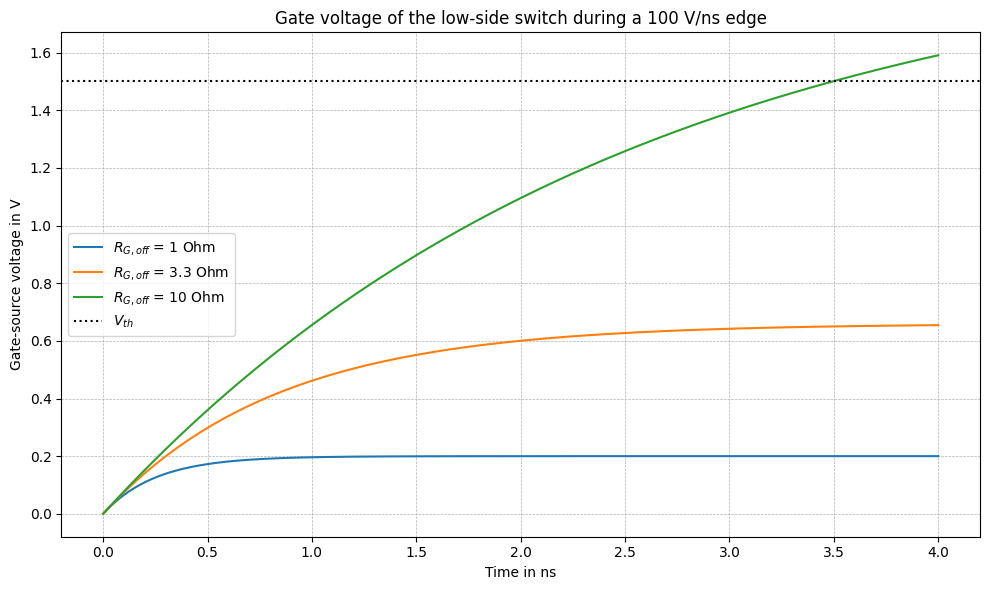

v_GS stays below V_th up to R_G,off = 9.1 Ohm


In [9]:
# Subtask 3.5.1 Switch node to heat sink
eps_0 = 8.854e-12                      # Unit F/m
C_hs = eps_0 * 6 * 48e-6 / 0.25e-3     # Unit F
print(f"C = {C_hs*1e12:.1f} pF, i = {C_hs*100e9:.2f} A at 100 V/ns, Q = {C_hs*400*1e9:.1f} nC per edge at 400 V")

# Subtask 3.5.2 Gate voltage of the low-side switch during the edge
C_GD, C_GS, dvdt, t_edge, V_th = 2e-12, 250e-12, 100e9, 4e-9, 1.5


def get_vGS(t, R):
    """Gate voltage in V during the edge (constant dv/dt, v_GS << v_DS)."""
    tau = R * (C_GS + C_GD)
    return R * C_GD * dvdt * (1 - np.exp(-t / tau))


if __name__ == "__main__":
    t = np.linspace(0, t_edge, 400)
    plt.figure(figsize=(10, 6))
    for R in [1, 3.3, 10]:
        plt.plot(t * 1e9, get_vGS(t, R), label=f'$R_{{G,off}}$ = {R} Ohm')
    plt.axhline(V_th, color='black', linestyle=':', label='$V_{th}$')
    plt.xlabel('Time in ns')
    plt.ylabel('Gate-source voltage in V')
    plt.title('Gate voltage of the low-side switch during a 100 V/ns edge')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 3.5.3 Largest R_G,off that keeps v_GS below V_th
    R_range = np.linspace(0.1, 20, 20000)
    v_end = get_vGS(t_edge, R_range)
    R_max = R_range[np.argmax(v_end > V_th)]
    print(f"v_GS stays below V_th up to R_G,off = {R_max:.1f} Ohm")


### 3.5.3 Solution

The heat-sink capacitance of $10.2~\mathrm{pF}$ carries $1~\mathrm{A}$ common-mode current during each $100~\mathrm{V/ns}$ edge. The gate voltage reaches $0.2~\mathrm{V}$ with $1~\Omega$ and $1.6~\mathrm{V}$ with $10~\Omega$ at the end of the edge; the limit is about $9~\Omega$. In practice the inductance of the gate loop and the tolerance of $V_\mathrm{th}$ (which falls with temperature) reduce this limit further.
